In [2]:
from sqlalchemy import create_engine
import os
from dotenv import load_dotenv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

load_dotenv()
host = os.getenv('DB_HOST')
port = os.getenv('DB_PORT')
name = os.getenv('DB_NAME')
user = os.getenv('DB_USER')
password = os.getenv('DB_PASSWORD')

engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{name}")
df = pd.read_sql_table('vc_vintage_curves', engine, 'sba')

## Vintage Curves

In [3]:
# Prep for figures: Change data type of fiscal year to string, rename cumulative sum columns to be more visual-friendly, 

df['approval_fiscal_year'] = df['approval_fiscal_year'].astype('str')
df = df.rename(columns={'cum_count_rate': 'Share of Charged-Off Loans', 'cum_dollar_rate': 'Share of Dollars Charged Off'})
prep = pd.melt(df, id_vars = ('approval_fiscal_year', 'age'), value_vars = ('Share of Charged-Off Loans', 'Share of Dollars Charged Off'), var_name='measure')

In [4]:
prep

,approval_fiscal_year,age,measure,value
0,2010,0,Share of Charged-Off Loans,0.000000
1,2010,1,Share of Charged-Off Loans,0.000000
2,2010,2,Share of Charged-Off Loans,0.000125
3,2010,3,Share of Charged-Off Loans,0.000425
4,2010,4,Share of Charged-Off Loans,0.001651
...,...,...,...,...
855,2019,20,Share of Dollars Charged Off,0.014355
856,2019,21,Share of Dollars Charged Off,0.015348
857,2019,22,Share of Dollars Charged Off,0.016973
858,2019,23,Share of Dollars Charged Off,0.017985


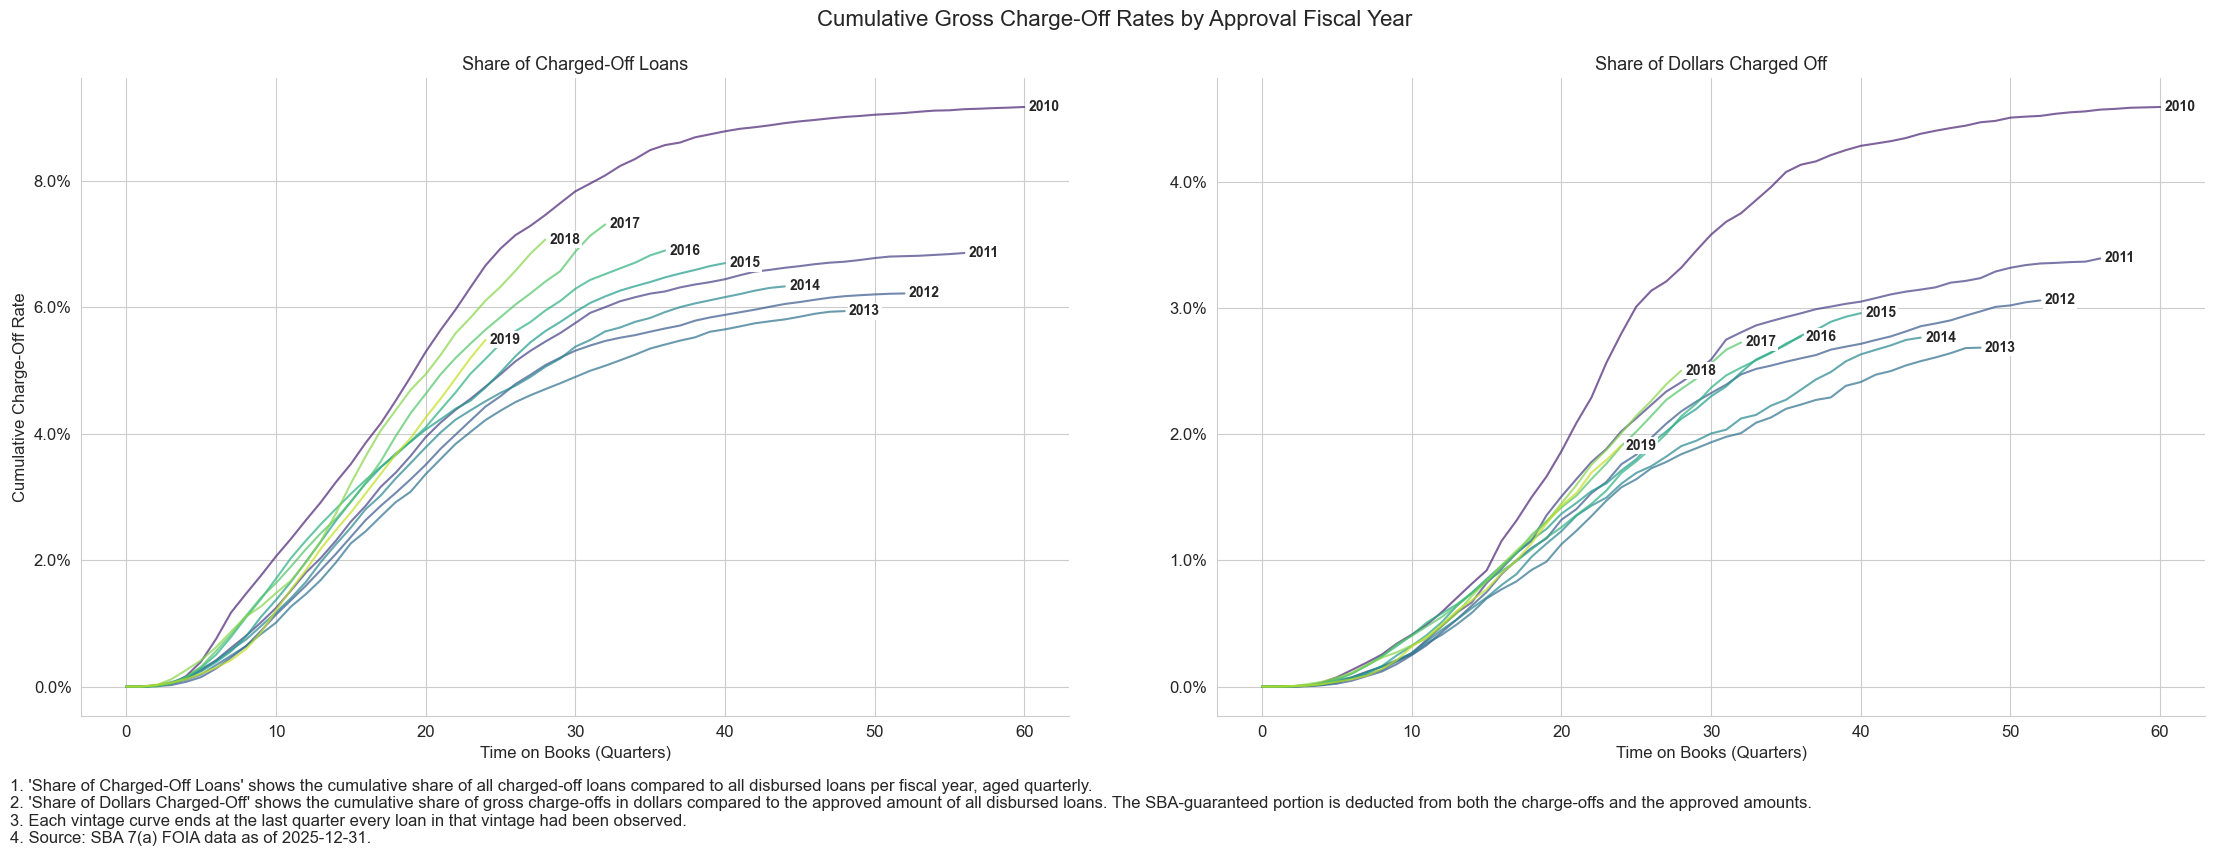

In [ ]:
# Plotting the vintage curves from FY2010-2019 with quarterly age granularity.

sns.set_style('whitegrid')

g = sns.relplot(
    kind='line',
    data=prep,
    x='age',
    y='value',
    col='measure',
    facet_kws={'sharey': False},
    hue='approval_fiscal_year',
    palette='viridis',
    alpha=0.7,
    height=8.5, 
    aspect=1.3,
    legend=False
    )

for meas, ax in g.axes_dict.items():
    m = prep[prep['measure'] == meas]
    for v in m['approval_fiscal_year'].unique():
        x = m[m['approval_fiscal_year'] == v]['age'].max()
        y = m[(m['approval_fiscal_year'] == v) & (m['age'] == x)]['value'].max()
        ax.text(x + 0.3, y, str(v), va='center', fontsize=10, weight='semibold', bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(labelsize=12)

notes = "\n".join([
                   "1. 'Share of Charged-Off Loans' shows the cumulative share of all charged-off loans compared to all disbursed loans per fiscal year, aged quarterly.",
                   "2. 'Share of Dollars Charged-Off' shows the cumulative share of gross charge-offs in dollars compared to the approved amount of all disbursed loans. The SBA-guaranteed portion is deducted from both the charge-offs and the approved amounts.",
                   "3. Each vintage curve ends at the last quarter every loan in that vintage had been observed.",
                   "4. Source: SBA 7(a) FOIA data as of 2025-12-31."
])

g.set_axis_labels('Time on Books (Quarters)', 'Cumulative Charge-Off Rate', fontsize=12)
g.set_titles('{col_name}', size=13)
g.figure.suptitle("Cumulative Gross Charge-Off Rates by Approval Fiscal Year", fontsize=16)
g.figure.subplots_adjust(wspace=0.15, top=0.9, bottom=0.15)
g.figure.text(0,  0, notes, fontsize=12)
plt.show()

## Prior Testing

**Prior 1: "FY2010's cumulative count rate at age 6 quarters is higher than at least 7 of the other 9 vintages."**

In [6]:
max_rates_age_six = df[df['age'] == 6].groupby('approval_fiscal_year')['Share of Charged-Off Loans'].max()
max_rates_age_six.sort_values(ascending=False)


approval_fiscal_year
2010    0.007530
2018    0.006218
2017    0.005617
2016    0.005036
2011    0.004156
2014    0.004088
2015    0.003861
2013    0.003384
2019    0.002978
2012    0.002848
Name: Share of Charged-Off Loans, dtype: float64

**Result:** __Prior is correct__. FY2010 has the highest cumulative count rate of all vintages at age 6. 0.75% of FY2010 loans had charged-off at age 6, with FY2018 and FY2017 loans following at rates of 0.62% and 0.56%.

**Prior 2: "For vintages with at least 40 quarters in age, at least 50% of the age-40 count rate is reached by age 20 as a result of the short-term loan effect on charge-off risk."**

In [8]:
forty_q = df[df['age'] == 40].groupby('approval_fiscal_year')['Share of Charged-Off Loans'].max()

twenty_q = df[df['age'] == 20].groupby('approval_fiscal_year')['Share of Charged-Off Loans'].max()
twenty_q = twenty_q[twenty_q.index.isin(forty_q.index)]

ratios = twenty_q / forty_q
ratios


approval_fiscal_year
2010    0.602506
2011    0.612016
2012    0.596422
2013    0.594406
2014    0.613973
2015    0.606787
Name: Share of Charged-Off Loans, dtype: float64

In [9]:
"""
Query adds term_bin representing short and long-term loans and excludes approval fiscal years with max ages below 40 . 
Charge-off ages are calculated and split between short term and long term term bins within each approval fiscal year (numerator).
Total number of charge-offs for each approval fiscal year is calculated (denominator).
Numerators and denominators are joined to the spine so ages with no charge-offs are still represented.
Cumulative sums for numerators are pulled for each vintage.
Ratios of short-term charge-offs to total and long-term charge-offs to total are calculated.
"""

terms = """
            WITH cohort AS (
                SELECT vc.*, r.term_bin
                FROM sba.vc_population_vw AS vc
                INNER JOIN (SELECT loan_id,
                                   CASE WHEN term_in_months BETWEEN 1 AND 60
                                        THEN 'Short-term'
                                        WHEN term_in_months > 60
                                        THEN 'Over 60 months'
                                        END AS term_bin
                            FROM sba.loans_raw
                            WHERE term_in_months IS NOT NULL
                                AND term_in_months <> 0) AS r
                    USING(loan_id)
                WHERE approval_fiscal_year IN (2010, 2011, 2012, 2013, 2014, 2015)
                ),

            age_chgoffs AS (
                SELECT *,
                       AGE(
                        charge_off_date, 
                        approval_date
                        ) AS charge_off_inter
                FROM cohort
                WHERE loan_status = 'CHGOFF'
                ),

            q_age_chgoffs AS (
                SELECT *,
                       ((EXTRACT(YEAR FROM charge_off_inter) * 12 + EXTRACT(MONTH FROM charge_off_inter))::integer / 3) AS charge_off_age
                FROM age_chgoffs
                ),

            numerators AS (
                SELECT approval_fiscal_year, 
                       charge_off_age,
                       COUNT(*) FILTER (WHERE term_bin = 'Short-term') AS short_chgoff_loans,
                       COUNT(*) FILTER (WHERE term_bin = 'Over 60 months') AS long_chgoff_loans
                FROM q_age_chgoffs
                GROUP BY approval_fiscal_year, charge_off_age
                ),

            denominator AS (
                SELECT approval_fiscal_year, COUNT(*) FILTER (WHERE loan_status = 'CHGOFF') AS total_chgoffs
                FROM cohort
                GROUP BY approval_fiscal_year
                ),

            inputs AS (
                SELECT s.approval_fiscal_year,
                       s.age,
                       COALESCE(n.short_chgoff_loans, 0) AS short_chgoff_count,
                       COALESCE(n.long_chgoff_loans, 0) AS long_chgoff_count,
                       d.total_chgoffs
                FROM sba.vc_spine s
                LEFT JOIN numerators n
                    ON s.approval_fiscal_year = n.approval_fiscal_year
                    AND s.age = n.charge_off_age
                LEFT JOIN denominator d
                    ON s.approval_fiscal_year = d.approval_fiscal_year
                WHERE s.approval_fiscal_year IN (2010, 2011, 2012, 2013, 2014, 2015)
                ),

            cumsum AS (
                SELECT approval_fiscal_year,
                       age,
                       SUM(short_chgoff_count) OVER (
                          PARTITION BY approval_fiscal_year 
                          ORDER BY age
                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
                          ) AS cum_short_chgoffs,
                       SUM(long_chgoff_count) OVER (
                          PARTITION BY approval_fiscal_year 
                          ORDER BY age
                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
                          ) AS cum_long_chgoffs,
                        total_chgoffs
                FROM inputs
                )

            SELECT approval_fiscal_year,
                   age,
                   cum_short_chgoffs,
                   cum_long_chgoffs,
                   total_chgoffs,
                   (cum_short_chgoffs::numeric / total_chgoffs) AS cum_short_contribution,
                   (cum_long_chgoffs::numeric / total_chgoffs) AS cum_long_contribution
            FROM cumsum;
"""

query = pd.read_sql_query(terms, engine)

In [10]:
# Sum of contributions should be near 100% of the total charge-offs for each fiscal year at the last age.
# Sums will be less than one due to some charge-offs occurring after the curves' ends.

check = query.groupby(['approval_fiscal_year'])[['age', 'cum_short_contribution', 'cum_long_contribution']].max()
check['check'] = check['cum_short_contribution'] + check['cum_long_contribution']
check

,age,cum_short_contribution,cum_long_contribution,check
approval_fiscal_year,,,,
2010,60,0.499863,0.498769,0.998633
2011,56,0.580180,0.416613,0.996793
2012,52,0.644868,0.349752,0.994619
2013,48,0.604661,0.391178,0.995839
2014,44,0.606911,0.385221,0.992131
2015,40,0.582217,0.406802,0.989020


In [11]:
# Filtering dataframe for the two relevant ages to the prior: 20 and 40.

prior_two_ages = query[query['age'].isin([20, 40])]
prior_two_ages

,approval_fiscal_year,age,cum_short_chgoffs,cum_long_chgoffs,total_chgoffs,cum_short_contribution,cum_long_contribution
20,2010,20,920.0,1194.0,3657,0.251572,0.326497
40,2010,40,1745.0,1753.0,3657,0.477167,0.479355
81,2011,20,970.0,825.0,3118,0.311097,0.264593
101,2011,40,1697.0,1227.0,3118,0.544259,0.393521
138,2012,20,830.0,531.0,2416,0.343543,0.219785
158,2012,40,1495.0,779.0,2416,0.618791,0.322434
191,2013,20,778.0,580.0,2403,0.323762,0.241365
211,2013,40,1390.0,888.0,2403,0.578444,0.369538
240,2014,20,977.0,761.0,2923,0.334246,0.260349
260,2014,40,1731.0,1093.0,2923,0.592200,0.373931


In [ ]:
# Add new column to dataframe to show ratio of short-term charge-offs to long-term for each vintage & age bucket.

prior_two_ages['short_to_long_ratio'] = np.round(prior_two_ages['cum_short_contribution'] / prior_two_ages['cum_long_contribution'], 2)
prior_two_ages = prior_two_ages.set_index(['approval_fiscal_year'])
prior_two_ages

,age,cum_short_chgoffs,cum_long_chgoffs,total_chgoffs,cum_short_contribution,cum_long_contribution,short_to_long_ratio
approval_fiscal_year,,,,,,,
2010,20,920.0,1194.0,3657,0.251572,0.326497,0.77
2010,40,1745.0,1753.0,3657,0.477167,0.479355,1.00
2011,20,970.0,825.0,3118,0.311097,0.264593,1.18
2011,40,1697.0,1227.0,3118,0.544259,0.393521,1.38
2012,20,830.0,531.0,2416,0.343543,0.219785,1.56
2012,40,1495.0,779.0,2416,0.618791,0.322434,1.92
2013,20,778.0,580.0,2403,0.323762,0.241365,1.34
2013,40,1390.0,888.0,2403,0.578444,0.369538,1.57
2014,20,977.0,761.0,2923,0.334246,0.260349,1.28


In [13]:
prior_two_ages['short_to_long_ratio'].mean()

np.float64(1.345)

In [14]:
prior_two_ages[prior_two_ages['age'] == 20]['short_to_long_ratio'].mean()

np.float64(1.21)

In [15]:
prior_two_ages[prior_two_ages['age'] == 40]['short_to_long_ratio'].mean()

np.float64(1.4800000000000002)

In [21]:
idx = prior_two_ages.index.to_series()

prior_two_ages['short_chgoff_growth'] = np.where(idx == idx.shift(1),
                                                prior_two_ages['cum_short_contribution'] / prior_two_ages['cum_short_contribution'].shift(1),
                                                np.nan)

prior_two_ages['long_chgoff_growth'] = np.where(idx == idx.shift(1),
                                                prior_two_ages['cum_long_contribution'] / prior_two_ages['cum_long_contribution'].shift(1),
                                                np.nan)

prior_two_ages

,age,cum_short_chgoffs,cum_long_chgoffs,total_chgoffs,cum_short_contribution,cum_long_contribution,short_to_long_ratio,short_chgoff_growth,long_chgoff_growth
approval_fiscal_year,,,,,,,,,
2010,20,920.0,1194.0,3657,0.251572,0.326497,0.77,NaN,NaN
2010,40,1745.0,1753.0,3657,0.477167,0.479355,1.00,1.896739,1.468174
2011,20,970.0,825.0,3118,0.311097,0.264593,1.18,NaN,NaN
2011,40,1697.0,1227.0,3118,0.544259,0.393521,1.38,1.749485,1.487273
2012,20,830.0,531.0,2416,0.343543,0.219785,1.56,NaN,NaN
2012,40,1495.0,779.0,2416,0.618791,0.322434,1.92,1.801205,1.467043
2013,20,778.0,580.0,2403,0.323762,0.241365,1.34,NaN,NaN
2013,40,1390.0,888.0,2403,0.578444,0.369538,1.57,1.786632,1.531034
2014,20,977.0,761.0,2923,0.334246,0.260349,1.28,NaN,NaN


In [ ]:
# Minus one to get the percentage increase rather than ratio

prior_two_ages['short_chgoff_growth'].mean() - 1

np.float64(0.8046846438926094)

In [ ]:
# Minus one to get the percentage increase rather than ratio

prior_two_ages['long_chgoff_growth'].mean() - 1

np.float64(0.47160053729313756)

**Result: Threshold is correct, cause is not supported.**  All six vintages observed for at least 40 quarters (FY2010-2015) had 59.4% to 61.4% of their total charge-offs at age 40 reported by age 20, above my threshold of 50%. Short-term charge-offs exceed long-term charge-offs in 10 of 12 vintage/age pairs reported, as represented by the short_to_long_ratio.

The two growth columns compare each term bin's cumulative charge-offs at age 40 to those reported at age 20. Short-term charge-offs actually grew more after age 20 than long-term charge-offs; short-term showed an average growth of 80.5% versus 47.2% for long-term. If short-term loans were the cause for 60% of age 40 charge-offs being reached by age 20, then I'd expect them to be front-loaded, with most of their charge-offs reported by age 20 and less growth afterward. Instead, we see the opposite effect, so I cannot claim the second half of my prior is correct.